In [21]:
!pip install matplotlib

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as ticker

sns.set_theme(style= 'whitegrid')
plt.rcParams["figure.figsize"] = (10,5)
df = pd.read_csv("../data/processed/online_retail_clean.csv", parse_dates= ["InvoiceDate"],dtype= {'CustomerID' : str})
print(df.shape, df.dtypes)

(541909, 15) InvoiceNo                 str
StockCode                 str
Description               str
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID                str
Country                   str
IsCancelled              bool
Year                    int64
Month                   int64
Day                     int64
Hour                    int64
DayOfWeek                 str
Revenue               float64
dtype: object


In [25]:
admin_codes = df[df['StockCode'].astype(str).str.isalpha()]
print(admin_codes['StockCode'].value_counts())

StockCode
POST         1256
DOT           710
M             571
D              77
S              63
AMAZONFEE      34
CRUK           16
DCGSSGIRL      13
DCGSSBOY       11
PADS            4
B               3
m               1
Name: count, dtype: int64


#Revenue        = sum of Revenue column (net of cancellations)
#Gross Revenue  = sum of Revenue where IsCancelled == False
#Orders         = count of distinct InvoiceNo
#AOV            = Gross Revenue / Orders
#Customers      = count of distinct CustomerID excluding "Null"/"nan"

In [23]:
gross = df[~df["IsCancelled"]]
print(gross.shape, gross.dtypes)

(532621, 15) InvoiceNo                 str
StockCode                 str
Description               str
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID                str
Country                   str
IsCancelled              bool
Year                    int64
Month                   int64
Day                     int64
Hour                    int64
DayOfWeek                 str
Revenue               float64
dtype: object


In [24]:

summary = {
    "Total Revenue (net)":   df['Revenue'].sum(),
    "Gross Revenue":         gross["Revenue"].sum(),
    "Total Orders":          gross['InvoiceNo'].nunique(),
    "Unique customers":      gross.loc[gross["CustomerID"].astype(str).str.isdigit(), "CustomerID"].nunique(),
    "Unique products":       gross["StockCode"].nunique(),
    "Countries":             gross['Country'].nunique(),
    "Average order value":   gross["Revenue"].sum() / gross["InvoiceNo"].nunique(),
    "Avg line items/order":  len(gross) / gross["InvoiceNo"].nunique(),
}

for k, v in summary.items():
    print(f"{k:28s} {v:,.2f}")

Total Revenue (net)          9,747,747.93
Gross Revenue                10,644,560.42
Total Orders                 22,064.00
Unique customers             4,339.00
Unique products              4,059.00
Countries                    38.00
Average order value          482.44
Avg line items/order         24.14


In [26]:
non_product_codes = ["POST", "BANK CHARGES", "DOT", "M", "D", "C2", "S", "B"]

product_view = gross[~gross["StockCode"].isin(non_product_codes)]

In [42]:
figures_dir = "../reports/figures/"

## Monthly Revenue Trend (Line Plot)

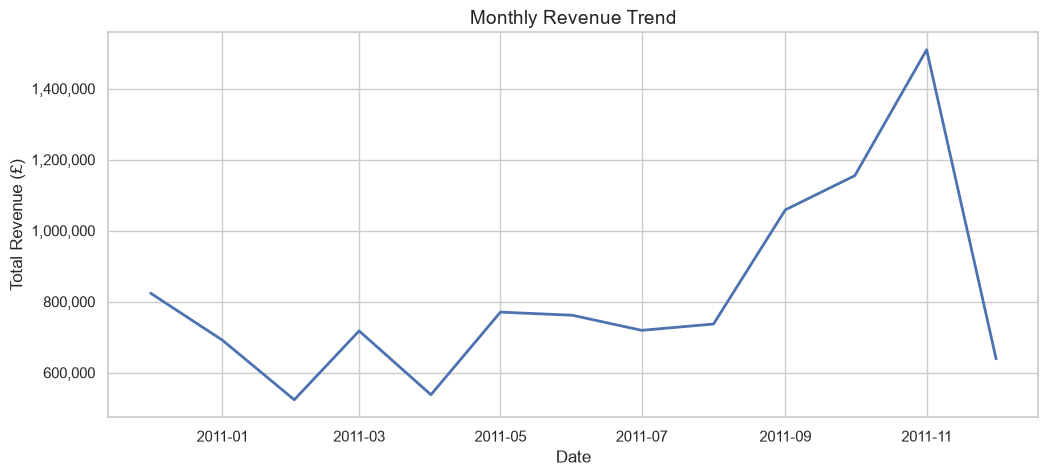

In [43]:

monthly_revenue = gross.groupby(['Year', 'Month'])['Revenue'].sum().reset_index()

monthly_revenue['Date'] = pd.to_datetime(monthly_revenue[['Year', 'Month']].assign(Day=1))

plt.figure(figsize= (12,5))
sns.lineplot(data = monthly_revenue, x= 'Date', y='Revenue', markers= 'o', linewidth=2)
plt.title("Monthly Revenue Trend", fontsize =14)
plt.ylabel("Total Revenue (£)")
plt.xlabel('Date')

plt.gca().yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
plt.savefig(f'{figures_dir}01_monthly_revenue_trend.png', dpi = 300, bbox_inches = 'tight')
plt.show()


### Top 10 Countries by Revenue (Horizontal Bar Chart)

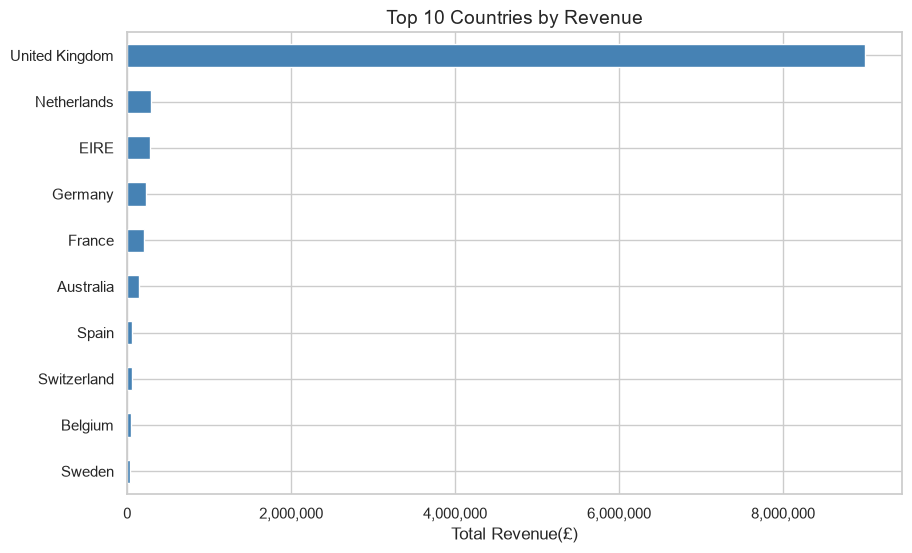

In [44]:
top_countries = gross.groupby('Country')['Revenue'].sum().nlargest(10).sort_values(ascending= True)

plt.figure(figsize=(10,6))
top_countries.plot(kind= "barh", color = "steelblue")
plt.title("Top 10 Countries by Revenue", fontsize=14)
plt.xlabel("Total Revenue(£)")
plt.ylabel("")
plt.gca().xaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
plt.savefig(f'{figures_dir}02_top_countries_by_revenue.png', dpi = 300, bbox_inches = 'tight')
plt.show()

#### 3. Top 10 Products by Revenue (Horizontal Bar Chart)

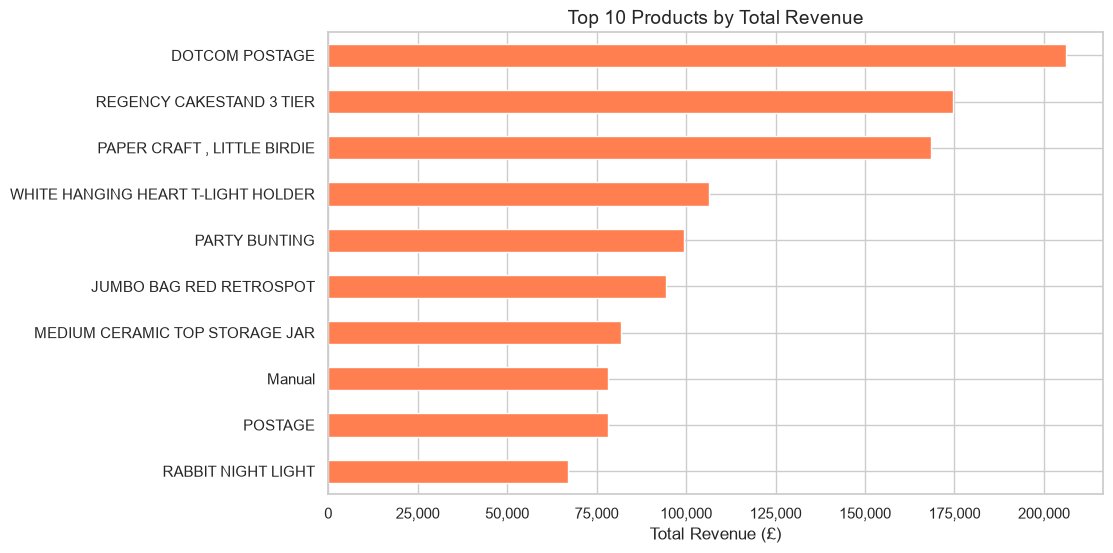

In [45]:
top_products_rev = gross.groupby("Description")["Revenue"].sum().nlargest(10).sort_values(ascending=True)

plt.figure(figsize=(10, 6))
top_products_rev.plot(kind="barh", color="coral")
plt.title("Top 10 Products by Total Revenue", fontsize=14)
plt.xlabel("Total Revenue (£)")
plt.ylabel("")
plt.gca().xaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
plt.savefig(f'{figures_dir}03_top_products_by_revenue', dpi = 300, bbox_inches = 'tight')
plt.show()


 #### Top 10 Products by Quantity (Horizontal Bar Chart)

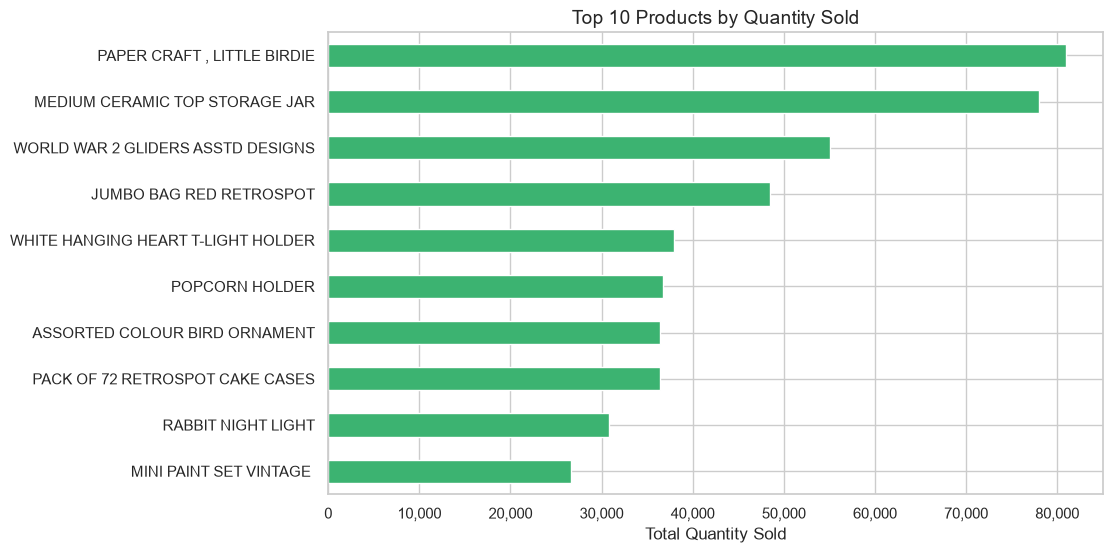

In [47]:
top_products_qty = gross.groupby("Description")["Quantity"].sum().nlargest(10).sort_values(ascending=True)

plt.figure(figsize=(10, 6))
top_products_qty.plot(kind="barh", color="mediumseagreen")
plt.title("Top 10 Products by Quantity Sold", fontsize=14)
plt.xlabel("Total Quantity Sold")
plt.ylabel("")
plt.gca().xaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
plt.savefig(f'{figures_dir}04_top_products_quantity.png', dpi = 300, bbox_inches = 'tight')
plt.show()


#### Order Value Distribution (Histogram)

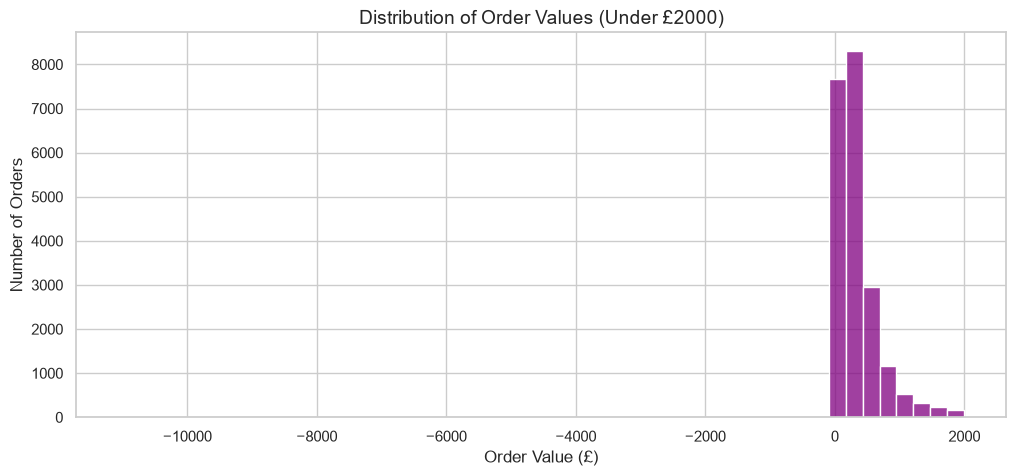

In [48]:

order_values = gross.groupby("InvoiceNo")["Revenue"].sum()

plt.figure(figsize=(12, 5))

sns.histplot(order_values[order_values < 2000], bins=50, color="purple")
plt.title("Distribution of Order Values (Under £2000)", fontsize=14)
plt.xlabel("Order Value (£)")
plt.ylabel("Number of Orders")
plt.savefig(f'{figures_dir}05_order_value_distribution.png', dpi = 300, bbox_inches = 'tight')
plt.show()


####  Orders by Hour of Day (Vertical Bar Chart)

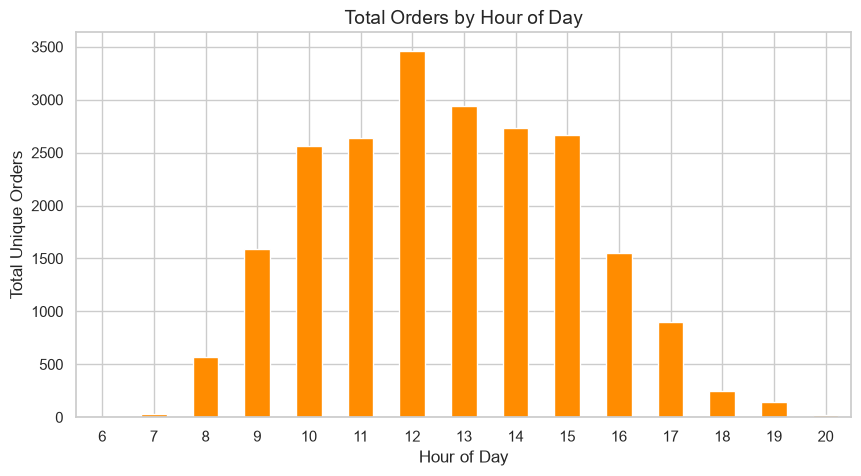

In [49]:

orders_by_hour = gross.groupby("Hour")["InvoiceNo"].nunique()

plt.figure(figsize=(10, 5))
orders_by_hour.plot(kind="bar", color="darkorange")
plt.title("Total Orders by Hour of Day", fontsize=14)
plt.xlabel("Hour of Day")
plt.ylabel("Total Unique Orders")
plt.xticks(rotation=0)
plt.savefig(f'{figures_dir}06_orders_by_hour_of_day.png', dpi = 300, bbox_inches = 'tight')
plt.show()
